# Visualisasi Hasil Eksperimen RankUp + TabM

Notebook ini merangkum `metrics.csv` dari eksperimen sweep fraksi label. Fokus utamanya adalah:

1. bagaimana performa berubah saat label bertambah,
2. seberapa besar peningkatan RankUp dibanding **Supervised** dengan jumlah label yang sama,
3. metode mana yang konsisten baik pada lima metrik, dan
4. trade-off performa terhadap waktu training.

> Arah metrik: **R², Spearman, QWK lebih besar lebih baik**; **MAE dan RMSE lebih kecil lebih baik**. QWK dipakai sebagai tampilan utama karena target eksperimen bersifat ordinal.

In [27]:
from pathlib import Path
from IPython.display import Markdown, display
import warnings

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "axes.titleweight": "bold"})

METRICS = ["R2", "Spearman", "MAE", "RMSE", "QWK"]
HIGHER_IS_BETTER = {"R2": True, "Spearman": True, "MAE": False, "RMSE": False, "QWK": True}
FRACTIONS = [0.01, 0.10, 0.30]
METHODS = [
    "Supervised", "RankUp + Range-Limited", "RankUp + SCARF",
    "RankUp + TabCutMix", "RankUp + Gaussian Noise",
]
SHORT = {
    "Supervised": "Supervised", "RankUp + Range-Limited": "Range-Limited",
    "RankUp + SCARF": "SCARF", "RankUp + TabCutMix": "TabCutMix",
    "RankUp + Gaussian Noise": "Gaussian Noise", "Fully-Supervised": "Fully-Supervised",
}
COLORS = dict(zip(METHODS, sns.color_palette("colorblind", len(METHODS))))

candidates = [
    Path("results/rankup_tabm_fraction_results/metrics.csv"),
    Path("hasil-tabm/results/rankup_tabm_fraction_results/metrics.csv"),
]
CSV_PATH = next((path for path in candidates if path.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError("metrics.csv tidak ditemukan. Jalankan notebook dari root proyek atau folder hasil-tabm.")

OUTPUT_DIR = CSV_PATH.parent / "visualizations"
OUTPUT_DIR.mkdir(exist_ok=True)
df = pd.read_csv(CSV_PATH)
df["labeled_fraction"] = pd.to_numeric(df["labeled_fraction"])
print(f"Data: {CSV_PATH} | {len(df):,} run | output grafik: {OUTPUT_DIR}")

Data: results/rankup_tabm_fraction_results/metrics.csv | 400 run | output grafik: results/rankup_tabm_fraction_results/visualizations


## 1. Pemeriksaan data

Sel ini memastikan kombinasi eksperimen lengkap sebelum grafik dibuat. `Fully-Supervised` memang hanya memiliki fraksi 100%, sedangkan lima metode lain memiliki fraksi 1%, 10%, dan 30%.

In [28]:
required = {"dataset", "experiment", "labeled_fraction", "n_labeled", "seed", "training_seconds", *METRICS}
missing = required - set(df.columns)
assert not missing, f"Kolom wajib tidak ada: {sorted(missing)}"
assert not df[list(required)].isna().any().any(), "Ada nilai kosong pada kolom analisis"
assert not df.duplicated(["dataset", "experiment", "labeled_fraction", "seed"]).any(), "Ada run duplikat"

coverage = (df.groupby(["dataset", "experiment", "labeled_fraction"])
              .agg(runs=("seed", "nunique"), labels=("n_labeled", "median"))
              .reset_index())
display(pd.DataFrame({
    "Ringkasan": ["Dataset", "Metode", "Seed", "Total run", "Hardware"],
    "Nilai": [df.dataset.nunique(), df.experiment.nunique(), df.seed.nunique(), len(df), ", ".join(map(str, df.hardware.unique()))],
}).style.hide(axis="index"))
display(coverage.pivot_table(index=["dataset", "experiment"], columns="labeled_fraction", values="runs", fill_value=0).astype(int))

Ringkasan,Nilai
Dataset,5
Metode,6
Seed,5
Total run,400
Hardware,Tesla T4


labeled_fraction                             0.01  0.10  0.30  1.00
dataset             experiment                                     
ESL                 Fully-Supervised            0     0     0     5
                    RankUp + Gaussian Noise     5     5     5     0
                    RankUp + Range-Limited      5     5     5     0
                    RankUp + SCARF              5     5     5     0
                    RankUp + TabCutMix          5     5     5     0
                    Supervised                  5     5     5     0
LEV                 Fully-Supervised            0     0     0     5
                    RankUp + Gaussian Noise     5     5     5     0
                    RankUp + Range-Limited      5     5     5     0
                    RankUp + SCARF              5     5     5     0
                    RankUp + TabCutMix          5     5     5     0
                    Supervised                  5     5     5     0
Melbourne Airbnb    Fully-Supervised            0     0     0     5
                    RankUp + Gaussian Noise     5     5     5     0
                    RankUp + Range-Limited      5     5     5     0
                    RankUp + SCARF              5     5     5     0
                    RankUp + TabCutMix          5     5     5     0
                    Supervised                  5     5     5     0
NHANES              Fully-Supervised            0     0     0     5
                    RankUp + Gaussian Noise     5     5     5     0
                    RankUp + Range-Limited      5     5     5     0
                    RankUp + SCARF              5     5     5     0
                    RankUp + TabCutMix          5     5     5     0
                    Supervised                  5     5     5     0
Student Performance Fully-Supervised            0     0     0     5
                    RankUp + Gaussian Noise     5     5     5     0
                    RankUp + Range-Limited      5     5     5     0
                    RankUp + SCARF              5     5     5     0
                    RankUp + TabCutMix          5     5     5     0
                    Supervised                  5     5     5     0

## 2.1 Tabel skor: mean seed untuk semua metrik

Tabel ini adalah ringkasan utama yang bisa dibaca langsung: satu baris untuk setiap dataset–metode–fraksi, dan setiap skor adalah **mean antar-seed**. Tidak ada standar deviasi yang digunakan.

In [29]:
mean_seed = (df.groupby(["dataset", "experiment", "labeled_fraction"], as_index=False)[METRICS]
             .mean())
mean_seed_display = mean_seed.copy()
mean_seed_display["experiment"] = mean_seed_display["experiment"].map(SHORT)
mean_seed_display["labeled_fraction"] = mean_seed_display["labeled_fraction"].map(lambda x: f"{x:.0%}")
mean_seed_display = mean_seed_display.rename(columns={"dataset": "Dataset", "experiment": "Metode", "labeled_fraction": "Label"})
mean_seed_display = mean_seed_display[["Dataset", "Metode", "Label", *METRICS]]
display(mean_seed_display.style.format({metric: "{:.4f}" for metric in METRICS}).hide(axis="index"))
mean_seed.to_csv(OUTPUT_DIR / "mean_seed_metrics.csv", index=False)
print(f"Tabel mean seed disimpan ke: {OUTPUT_DIR / 'mean_seed_metrics.csv'}")

Dataset,Metode,Label,R2,Spearman,MAE,RMSE,QWK
ESL,Fully-Supervised,100%,0.8338,0.9243,0.3717,0.5461,0.9005
ESL,Gaussian Noise,1%,0.6436,0.8910,0.5608,0.7780,0.8584
ESL,Gaussian Noise,10%,0.8124,0.9257,0.4231,0.5791,0.8888
ESL,Gaussian Noise,30%,0.8035,0.9107,0.4102,0.5935,0.8804
ESL,Range-Limited,1%,0.6568,0.9024,0.5594,0.7547,0.8461
ESL,Range-Limited,10%,0.8256,0.9272,0.4147,0.5592,0.8932
ESL,Range-Limited,30%,0.8045,0.9086,0.4088,0.5922,0.8869
ESL,SCARF,1%,0.7401,0.9106,0.5109,0.6780,0.8038
ESL,SCARF,10%,0.8238,0.9264,0.4171,0.5623,0.8861
ESL,SCARF,30%,0.8057,0.9102,0.4073,0.5903,0.8899


Tabel mean seed disimpan ke: results/rankup_tabm_fraction_results/visualizations/mean_seed_metrics.csv


## 2.2 Heatmap angka mean seed untuk semua metrik

Setiap panel adalah satu metrik. Warna membantu melihat pola, sedangkan angka di dalam sel adalah nilai mean seed yang sebenarnya.

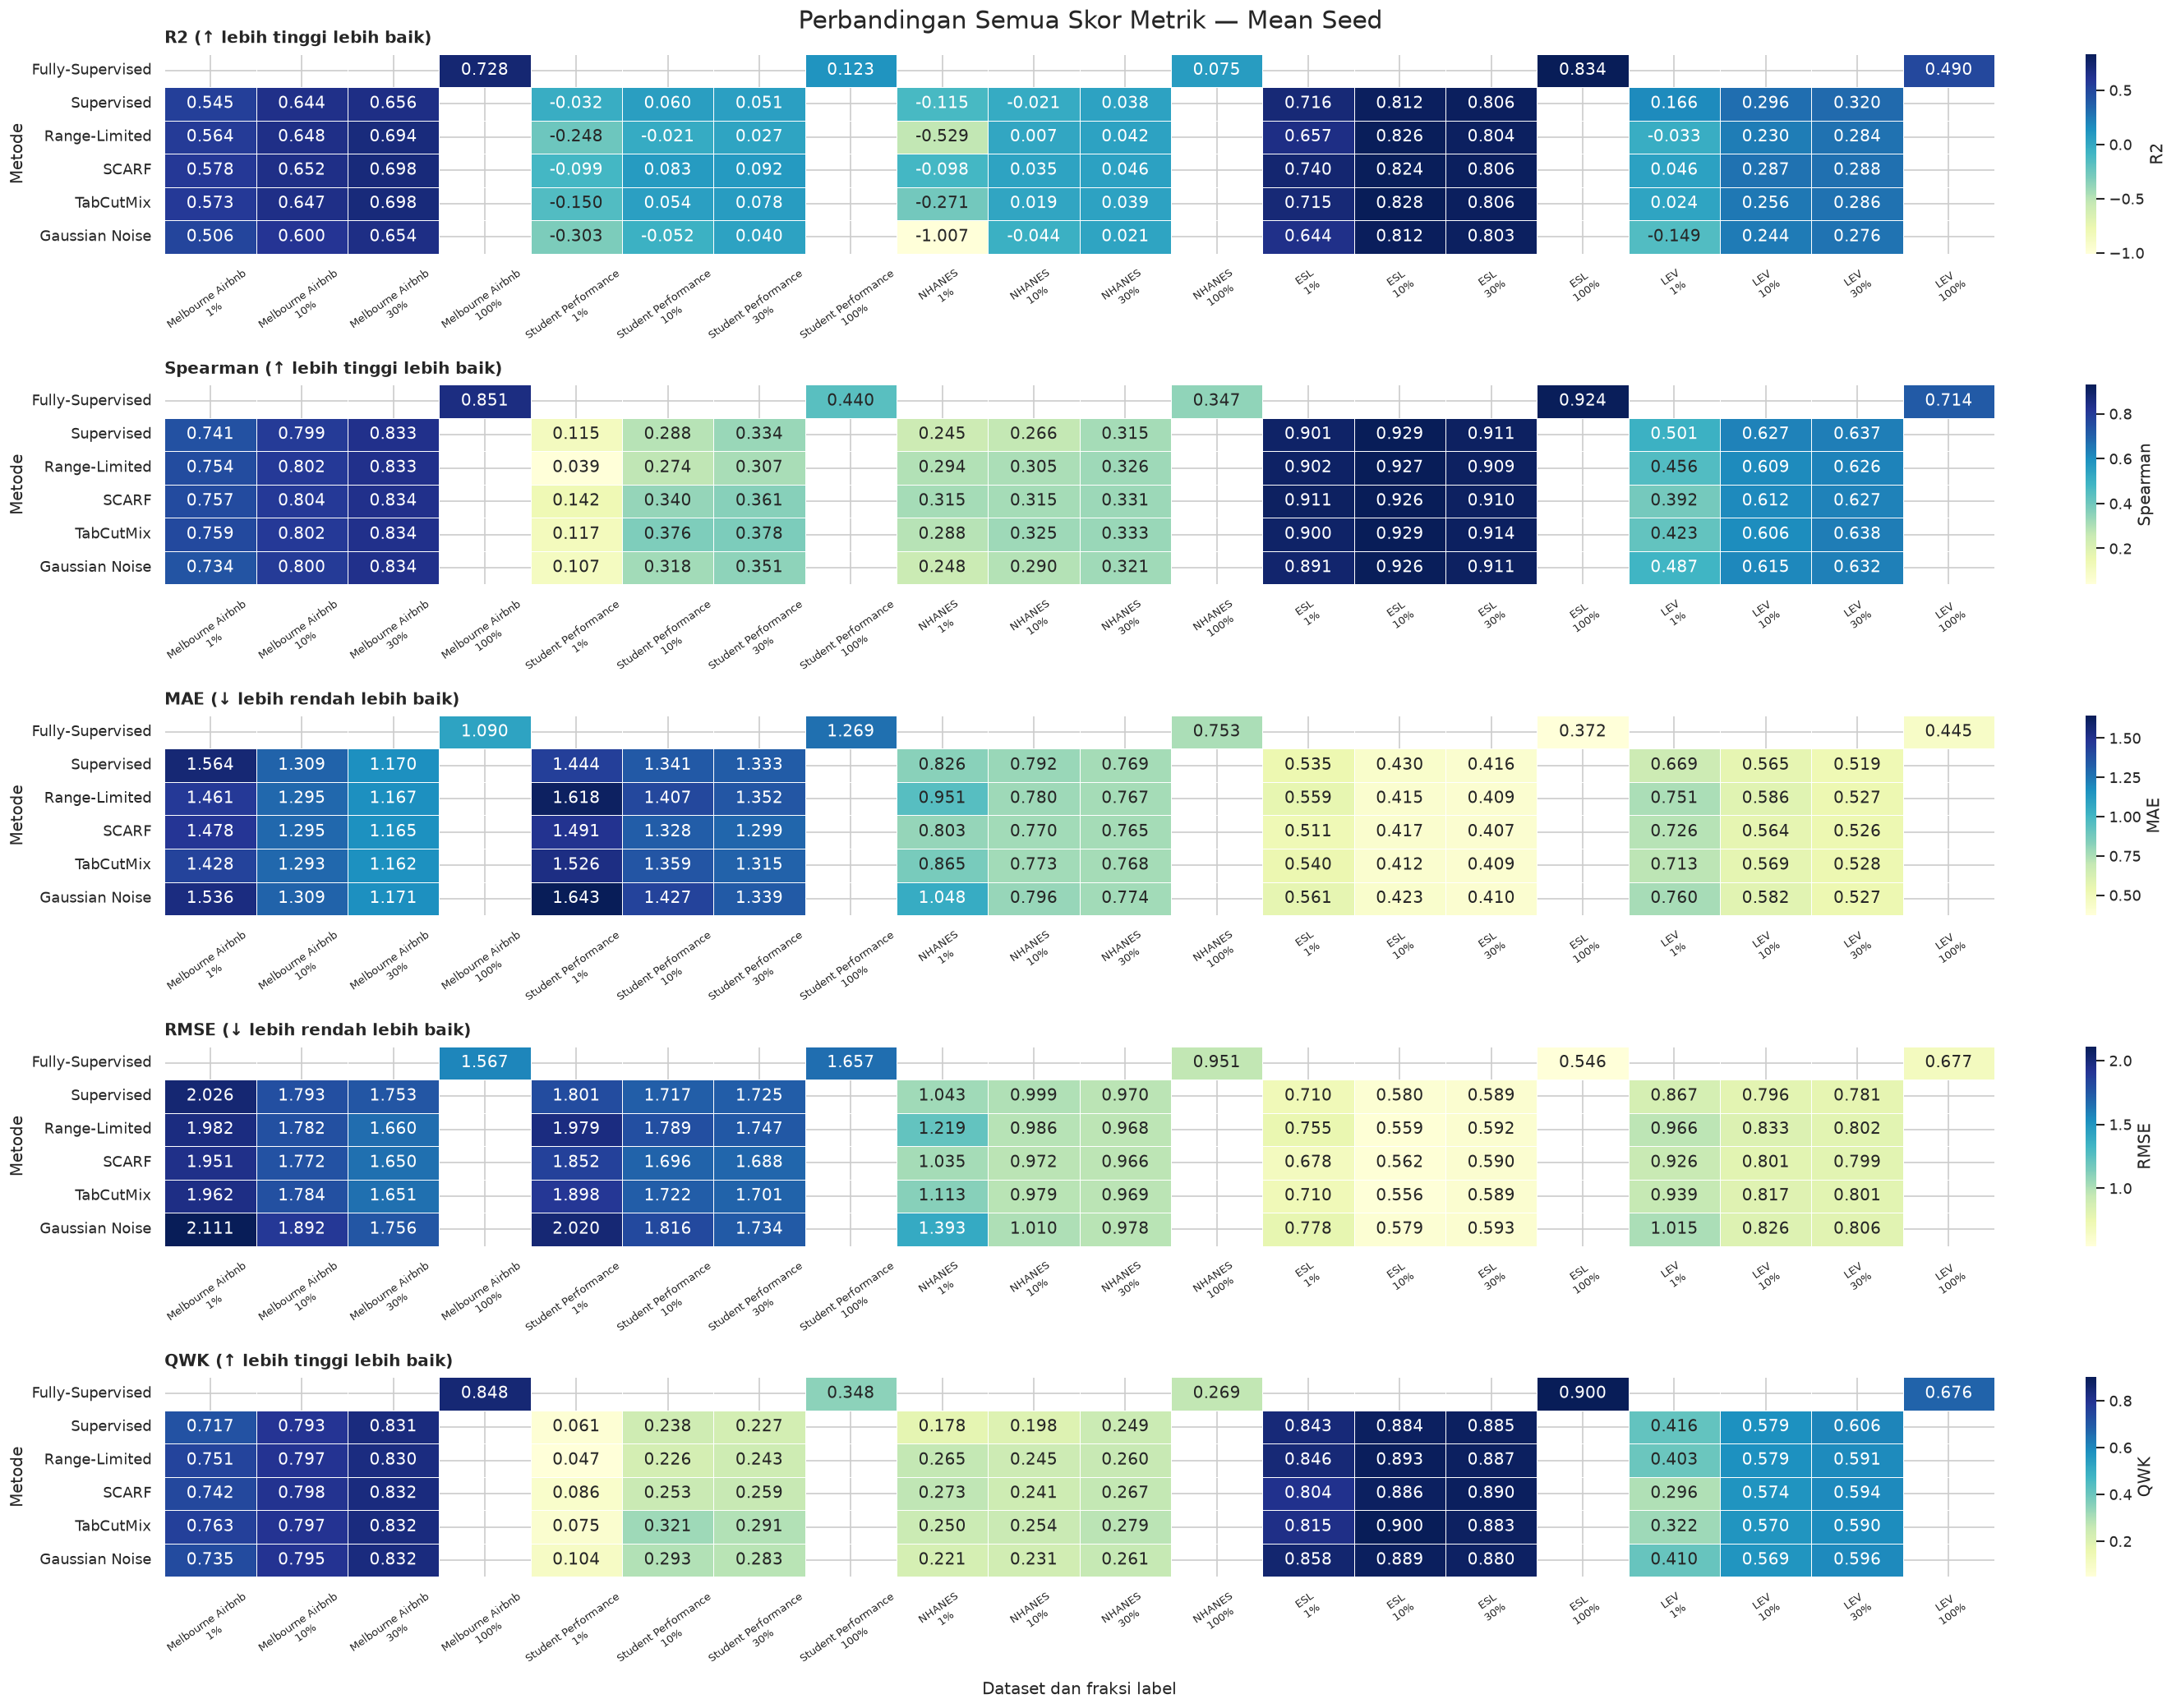

Heatmap semua metrik disimpan ke: results/rankup_tabm_fraction_results/visualizations/05_mean_seed_semua_metrik.png


In [30]:
datasets = df.dataset.drop_duplicates().tolist()
ALL_FRACTIONS = [0.01, 0.10, 0.30, 1.00]
ALL_EXPERIMENTS = ["Fully-Supervised", *METHODS]
column_order = [f"{dataset}\n{fraction:.0%}" for dataset in datasets for fraction in ALL_FRACTIONS]
mean_for_heatmap = mean_seed.copy()
mean_for_heatmap["Metode"] = mean_for_heatmap["experiment"].map(SHORT)
mean_for_heatmap["Kolom"] = mean_for_heatmap["dataset"] + "\n" + mean_for_heatmap["labeled_fraction"].map(lambda x: f"{x:.0%}")
method_order = [SHORT[experiment] for experiment in ALL_EXPERIMENTS]

fig, axes = plt.subplots(len(METRICS), 1, figsize=(22, 17), constrained_layout=True)
for ax, metric in zip(axes, METRICS):
    heat = (mean_for_heatmap.pivot(index="Metode", columns="Kolom", values=metric)
            .reindex(index=method_order, columns=column_order))
    finite = heat.to_numpy()[~np.isnan(heat.to_numpy())]
    vmin, vmax = finite.min(), finite.max()
    sns.heatmap(heat, mask=heat.isna(), annot=True, fmt=".3f", cmap="YlGnBu",
                vmin=vmin, vmax=vmax, linewidths=.5, linecolor="white",
                cbar_kws={"label": metric}, ax=ax)
    ax.set_title(f"{metric} ({'↑ lebih tinggi lebih baik' if HIGHER_IS_BETTER[metric] else '↓ lebih rendah lebih baik'})", loc="left", pad=8)
    ax.set_xlabel("" if metric != METRICS[-1] else "Dataset dan fraksi label")
    ax.set_ylabel("Metode")
    ax.tick_params(axis="x", rotation=35, labelsize=8)
fig.suptitle("Perbandingan Semua Skor Metrik — Mean Seed", fontsize=18, y=1.01)
fig.savefig(OUTPUT_DIR / "05_mean_seed_semua_metrik.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Heatmap semua metrik disimpan ke: {OUTPUT_DIR / '05_mean_seed_semua_metrik.png'}")

## 2. Tren QWK terhadap fraksi label

Setiap titik adalah **mean dari lima seed**. Garis hitam putus-putus adalah **Fully-Supervised**. Jarak antartitik dibuat sama agar 1%, 10%, dan 30% mudah dibandingkan.

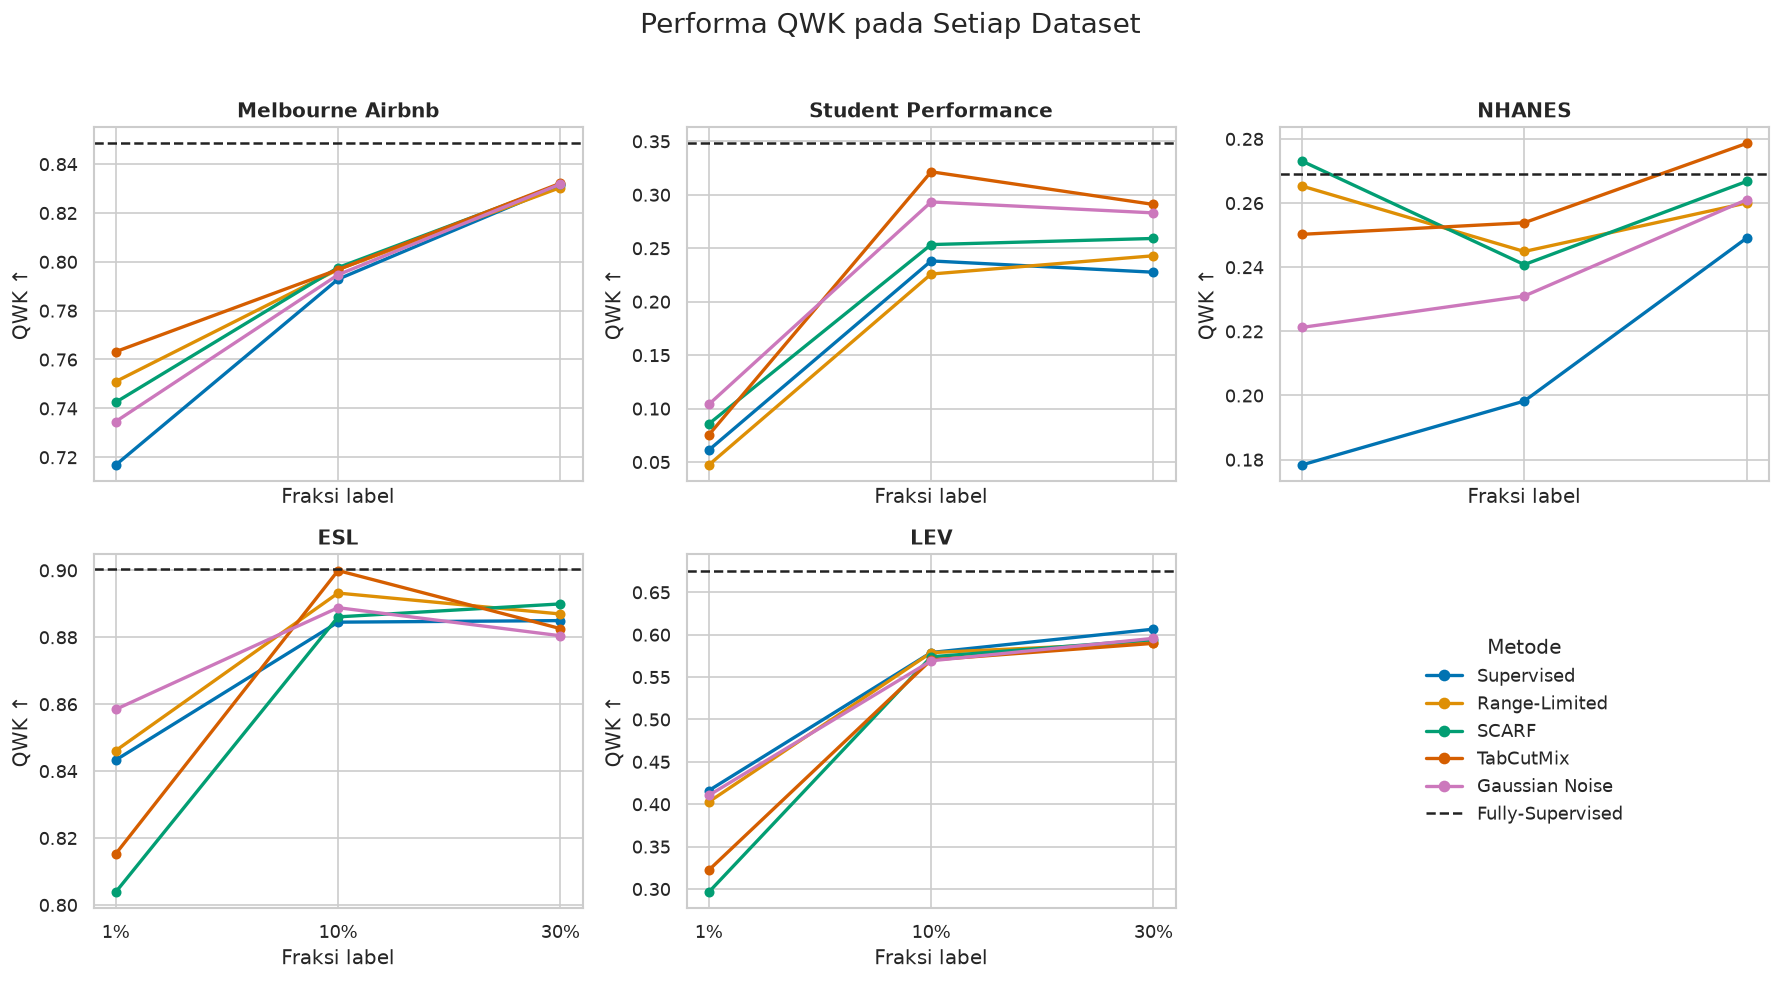

In [31]:
PRIMARY_METRIC = "QWK"  # ganti dengan salah satu METRICS bila ingin mengeksplorasi metrik lain
summary = (df[df.experiment.isin(METHODS)]
           .groupby(["dataset", "experiment", "labeled_fraction"], as_index=False)[PRIMARY_METRIC]
           .mean())
fully = df[df.experiment.eq("Fully-Supervised")].groupby("dataset")[PRIMARY_METRIC].mean()
datasets = df.dataset.drop_duplicates().tolist()
x = np.arange(len(FRACTIONS))

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, dataset in zip(axes.flat, datasets):
    part = summary[summary.dataset.eq(dataset)]
    for method in METHODS:
        values = part[part.experiment.eq(method)].set_index("labeled_fraction").reindex(FRACTIONS)
        mean = values[PRIMARY_METRIC].to_numpy()
        ax.plot(x, mean, marker="o", lw=2, ms=5, color=COLORS[method])
    ax.axhline(fully[dataset], color="#222222", ls="--", lw=1.5)
    ax.set_title(dataset)
    ax.set_xticks(x, ["1%", "10%", "30%"])
    ax.set_xlabel("Fraksi label")
    ax.set_ylabel(f"{PRIMARY_METRIC} ↑" if HIGHER_IS_BETTER[PRIMARY_METRIC] else f"{PRIMARY_METRIC} ↓")
axes.flat[-1].axis("off")
legend = [Line2D([0], [0], color=COLORS[m], marker="o", lw=2, label=SHORT[m]) for m in METHODS]
legend += [Line2D([0], [0], color="#222222", ls="--", lw=1.5, label="Fully-Supervised")]
axes.flat[-1].legend(handles=legend, loc="center", frameon=False, title="Metode")
fig.suptitle(f"Performa {PRIMARY_METRIC} pada Setiap Dataset", fontsize=17, y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"01_tren_{PRIMARY_METRIC.lower()}.png", bbox_inches="tight")
plt.show()

## 3. Apakah RankUp mengalahkan baseline berlabel sama?

Heatmap berikut menampilkan selisih rata-rata QWK terhadap **Supervised** pada dataset dan fraksi label yang sama. Biru berarti lebih baik; merah berarti lebih buruk. Ini perbandingan paling langsung untuk mengukur manfaat data unlabeled.

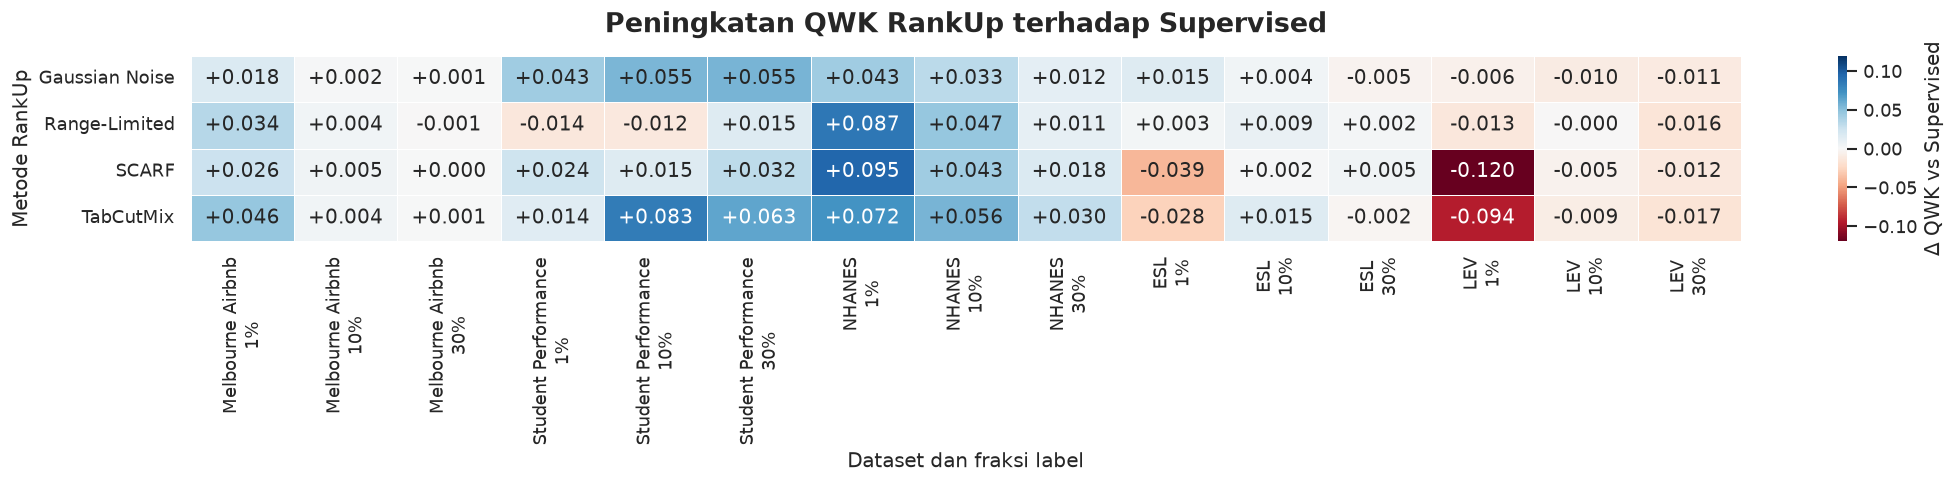

In [32]:
mean_qwk = (df[df.experiment.isin(METHODS)]
            .groupby(["dataset", "experiment", "labeled_fraction"], as_index=False)["QWK"].mean())
baseline = (mean_qwk[mean_qwk.experiment.eq("Supervised")]
            [["dataset", "labeled_fraction", "QWK"]].rename(columns={"QWK": "baseline"}))
delta = mean_qwk[~mean_qwk.experiment.eq("Supervised")].merge(baseline, on=["dataset", "labeled_fraction"])
delta["delta"] = delta["QWK"] - delta["baseline"]
delta["kolom"] = delta["dataset"] + "\n" + delta["labeled_fraction"].map(lambda x: f"{x:.0%}")
column_order = [f"{d}\n{f:.0%}" for d in datasets for f in FRACTIONS]
heat = delta.pivot(index="experiment", columns="kolom", values="delta").reindex(columns=column_order)
heat.index = heat.index.map(SHORT)

fig, ax = plt.subplots(figsize=(18, 4.2))
limit = np.nanmax(np.abs(heat.to_numpy()))
sns.heatmap(heat, cmap="RdBu", center=0, vmin=-limit, vmax=limit, annot=True, fmt="+.3f",
            linewidths=.5, cbar_kws={"label": "Δ QWK vs Supervised"}, ax=ax)
ax.set_title("Peningkatan QWK RankUp terhadap Supervised", fontsize=16, pad=14)
ax.set_xlabel("Dataset dan fraksi label")
ax.set_ylabel("Metode RankUp")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_delta_qwk_vs_supervised.png", bbox_inches="tight")
plt.show()

## 4. Konsistensi pada semua metrik

Karena skala kelima metrik berbeda, setiap metode diberi peringkat dalam tiap kombinasi dataset × seed × fraksi × metrik. Nilai di bawah adalah **rata-rata peringkat**: makin dekat ke 1 makin konsisten baik.

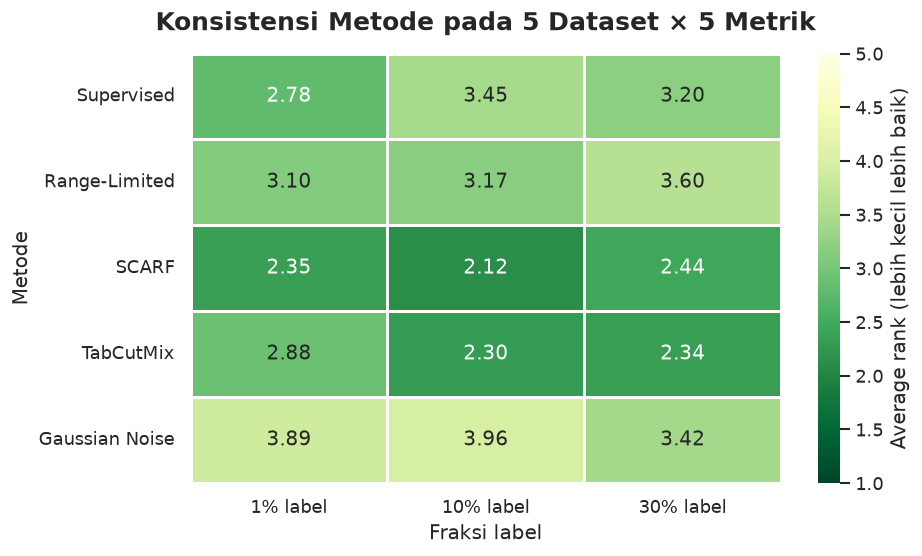

In [33]:
rank_source = df[df.experiment.isin(METHODS)].copy()
rank_columns = []
for metric in METRICS:
    column = f"rank_{metric}"
    rank_source[column] = rank_source.groupby(["dataset", "seed", "labeled_fraction"])[metric].rank(
        ascending=not HIGHER_IS_BETTER[metric], method="average")
    rank_columns.append(column)
rank_source["average_rank"] = rank_source[rank_columns].mean(axis=1)
rank_heat = (rank_source.groupby(["experiment", "labeled_fraction"])["average_rank"].mean()
             .unstack().reindex(METHODS))
rank_heat.index = rank_heat.index.map(SHORT)
rank_heat.columns = [f"{x:.0%} label" for x in rank_heat.columns]

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(rank_heat, cmap="YlGn_r", vmin=1, vmax=len(METHODS), annot=True, fmt=".2f",
            linewidths=.8, cbar_kws={"label": "Average rank (lebih kecil lebih baik)"}, ax=ax)
ax.set_title("Konsistensi Metode pada 5 Dataset × 5 Metrik", fontsize=15, pad=14)
ax.set_xlabel("Fraksi label")
ax.set_ylabel("Metode")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_average_rank_semua_metrik.png", bbox_inches="tight")
plt.show()

## 5. Biaya training relatif

Waktu setiap run dibagi waktu **Supervised** pada dataset, seed, dan fraksi label yang sama. Nilai 10× berarti training membutuhkan sekitar sepuluh kali waktu baseline. Median dipakai agar startup/warm-up GPU tidak mendominasi.

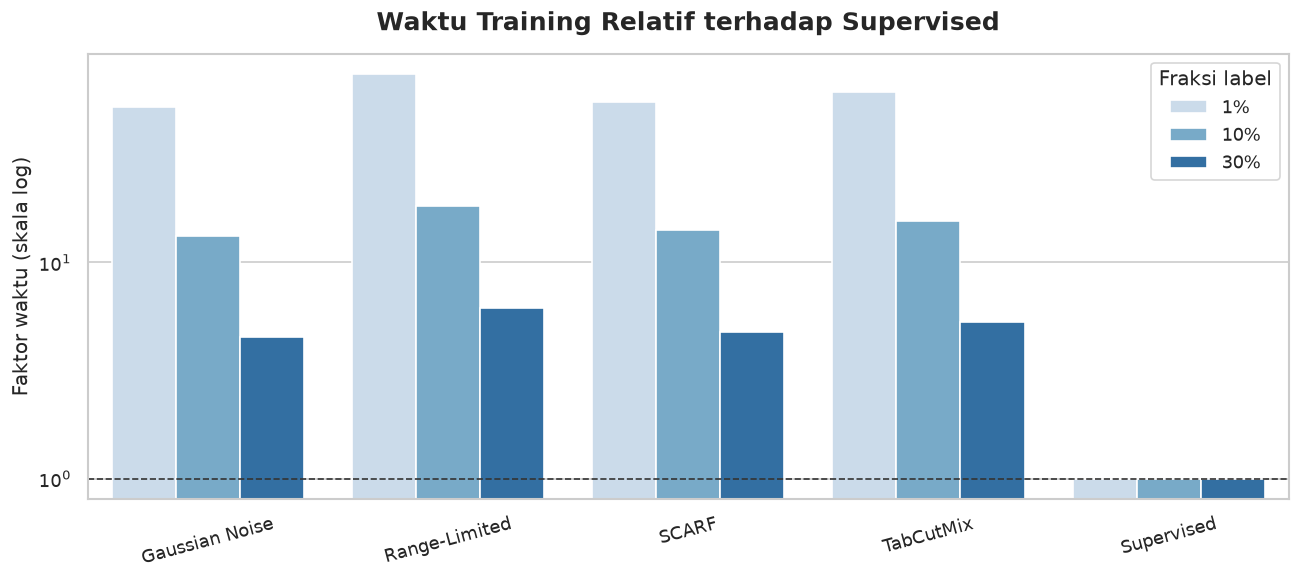

In [34]:
timing = df[df.experiment.isin(METHODS)].copy()
base_time = (timing[timing.experiment.eq("Supervised")]
             .set_index(["dataset", "seed", "labeled_fraction"])["training_seconds"])
timing["time_factor"] = timing.set_index(["dataset", "seed", "labeled_fraction"]).index.map(base_time)
timing["time_factor"] = timing["training_seconds"] / timing["time_factor"]
time_summary = (timing.groupby(["experiment", "labeled_fraction"])["time_factor"].mean()
                .rename("Mean faktor waktu").reset_index())
time_summary["Metode"] = time_summary.experiment.map(SHORT)
time_summary["Fraksi label"] = time_summary.labeled_fraction.map(lambda x: f"{x:.0%}")

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=time_summary, x="Metode", y="Mean faktor waktu", hue="Fraksi label",
            palette="Blues", edgecolor="white", ax=ax)
ax.axhline(1, color="#333333", ls="--", lw=1)
ax.set_yscale("log")
ax.set_title("Waktu Training Relatif terhadap Supervised", fontsize=15, pad=14)
ax.set_ylabel("Faktor waktu (skala log)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_waktu_training_relatif.png", bbox_inches="tight")
plt.show()

## 6. Tabel pemenang dan ringkasan otomatis

Pemenang ditentukan dari mean QWK antar-seed. Tabel ini menampilkan mean saja agar perbandingan skor tetap ringkas dan mudah dibaca.

In [35]:
qwk_stats = (df[df.experiment.isin(METHODS)]
             .groupby(["dataset", "labeled_fraction", "experiment"], as_index=False)["QWK"]
             .mean())
winners = qwk_stats.loc[qwk_stats.groupby(["dataset", "labeled_fraction"])["QWK"].idxmax()].copy()
supervised_qwk = qwk_stats[qwk_stats.experiment.eq("Supervised")].set_index(["dataset", "labeled_fraction"])["QWK"]
winners["gain_vs_supervised"] = [row["QWK"] - supervised_qwk.loc[(row["dataset"], row["labeled_fraction"])] for _, row in winners.iterrows()]
winners["experiment"] = winners.experiment.map(SHORT)
winners["labeled_fraction"] = winners.labeled_fraction.map(lambda x: f"{x:.0%}")
shown = winners.rename(columns={"dataset": "Dataset", "labeled_fraction": "Label", "experiment": "Metode terbaik",
                                  "QWK": "Mean QWK", "gain_vs_supervised": "Δ vs Supervised"})
display(shown.style.format({"Mean QWK": "{:.3f}", "Δ vs Supervised": "{:+.3f}"})
        .background_gradient(subset=["Δ vs Supervised"], cmap="RdBu", vmin=-shown["Δ vs Supervised"].abs().max(), vmax=shown["Δ vs Supervised"].abs().max())
        .hide(axis="index"))

rankup_wins = (winners["experiment"] != "Supervised").sum()
best_overall = rank_source.groupby("experiment")["average_rank"].mean().idxmin()
best_gain = delta.loc[delta.delta.idxmax()]
worst_gain = delta.loc[delta.delta.idxmin()]
display(Markdown(
    f"### Ringkasan\n"
    f"- RankUp menjadi pemenang QWK pada **{rankup_wins} dari {len(winners)}** kombinasi dataset–fraksi.\n"
    f"- Metode dengan average rank terbaik di seluruh metrik adalah **{SHORT[best_overall]}**.\n"
    f"- Peningkatan QWK terbesar: **{SHORT[best_gain.experiment]}**, {best_gain.dataset}, {best_gain.labeled_fraction:.0%} label (**{best_gain.delta:+.3f}**).\n"
    f"- Penurunan QWK terbesar: **{SHORT[worst_gain.experiment]}**, {worst_gain.dataset}, {worst_gain.labeled_fraction:.0%} label (**{worst_gain.delta:+.3f}**)."
))
print(f"Empat grafik tersimpan di: {OUTPUT_DIR.resolve()}")

Dataset,Label,Metode terbaik,Mean QWK,Δ vs Supervised
ESL,1%,Gaussian Noise,0.858,+0.015
ESL,10%,TabCutMix,0.900,+0.015
ESL,30%,SCARF,0.890,+0.005
LEV,1%,Supervised,0.416,+0.000
LEV,10%,Supervised,0.579,+0.000
LEV,30%,Supervised,0.606,+0.000
Melbourne Airbnb,1%,TabCutMix,0.763,+0.046
Melbourne Airbnb,10%,SCARF,0.798,+0.005
Melbourne Airbnb,30%,TabCutMix,0.832,+0.001
NHANES,1%,SCARF,0.273,+0.095


### Ringkasan
- RankUp menjadi pemenang QWK pada **12 dari 15** kombinasi dataset–fraksi.
- Metode dengan average rank terbaik di seluruh metrik adalah **SCARF**.
- Peningkatan QWK terbesar: **SCARF**, NHANES, 1% label (**+0.095**).
- Penurunan QWK terbesar: **SCARF**, LEV, 1% label (**-0.120**).

Empat grafik tersimpan di: /mnt/new-volume/Kuliah/Riset deep learning/task 2/hasil-tabm/results/rankup_tabm_fraction_results/visualizations


## 7. Rata-rata lintas semua dataset

Di sini mean seed dari masing-masing dataset dirata-ratakan lagi secara seimbang di lima dataset. Jadi setiap dataset memiliki bobot yang sama, terlepas dari jumlah baris datanya.

Metode,Label,R2,Spearman,MAE,RMSE,QWK
Fully-Supervised,100%,0.4500,0.6555,0.7857,1.0796,0.6083
Gaussian Noise,1%,-0.0622,0.4933,1.1096,1.4634,0.4657
Gaussian Noise,10%,0.3119,0.5895,0.9073,1.2245,0.5554
Gaussian Noise,30%,0.3592,0.6098,0.8442,1.1736,0.5704
Range-Limited,1%,0.0822,0.4893,1.0681,1.3804,0.4624
Range-Limited,10%,0.3379,0.5836,0.8965,1.1897,0.5479
Range-Limited,30%,0.3704,0.6002,0.8443,1.1538,0.5622
SCARF,1%,0.2334,0.5033,1.0019,1.2885,0.4403
SCARF,10%,0.3760,0.5995,0.8747,1.1605,0.5503
SCARF,30%,0.3860,0.6126,0.8324,1.1387,0.5683


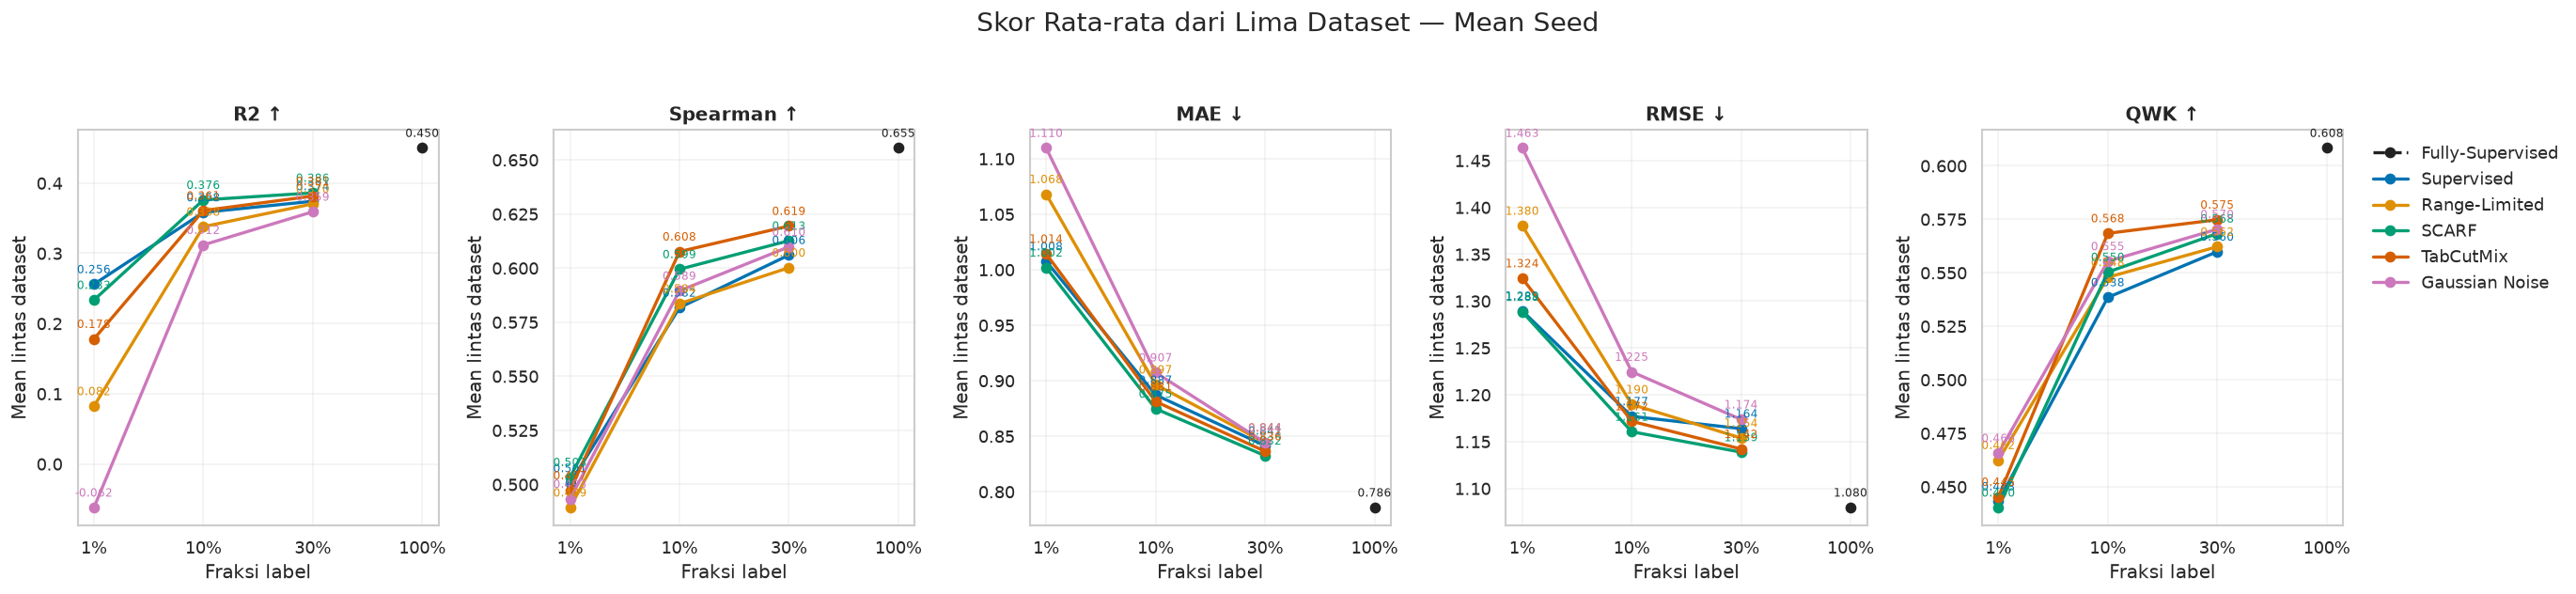

Tabel: results/rankup_tabm_fraction_results/visualizations/overall_mean_all_datasets.csv
Grafik: results/rankup_tabm_fraction_results/visualizations/06_mean_semua_dataset.png


In [36]:
overall_mean = (mean_seed.groupby(["experiment", "labeled_fraction"], as_index=False)[METRICS]
               .mean())
overall_display = overall_mean.copy()
overall_display["experiment"] = overall_display["experiment"].map(SHORT)
overall_display["labeled_fraction"] = overall_display["labeled_fraction"].map(lambda x: f"{x:.0%}")
overall_display = overall_display.rename(columns={"experiment": "Metode", "labeled_fraction": "Label"})
display(overall_display[["Metode", "Label", *METRICS]].style
        .format({metric: "{:.4f}" for metric in METRICS})
        .hide(axis="index"))
overall_mean.to_csv(OUTPUT_DIR / "overall_mean_all_datasets.csv", index=False)

fraction_order = [0.01, 0.10, 0.30, 1.00]
fig, axes = plt.subplots(1, len(METRICS), figsize=(23, 5), sharex=True)
for ax, metric in zip(axes, METRICS):
    for experiment in ALL_EXPERIMENTS:
        part = overall_mean[overall_mean.experiment.eq(experiment)].set_index("labeled_fraction").reindex(fraction_order)
        values = part[metric].to_numpy()
        color = "#222222" if experiment == "Fully-Supervised" else COLORS[experiment]
        linestyle = "--" if experiment == "Fully-Supervised" else "-"
        ax.plot(range(len(fraction_order)), values, marker="o", lw=2, color=color,
                linestyle=linestyle, label=SHORT[experiment])
        for x_pos, value in enumerate(values):
            if np.isfinite(value):
                ax.annotate(f"{value:.3f}", (x_pos, value), xytext=(0, 7), textcoords="offset points",
                            ha="center", fontsize=7, color=color)
    ax.set_title(f"{metric} {'↑' if HIGHER_IS_BETTER[metric] else '↓'}")
    ax.set_xticks(range(len(fraction_order)), ["1%", "10%", "30%", "100%"])
    ax.set_xlabel("Fraksi label")
    ax.set_ylabel("Mean lintas dataset")
    ax.grid(alpha=.25)
axes[-1].legend(bbox_to_anchor=(1.04, 1), loc="upper left", frameon=False)
fig.suptitle("Skor Rata-rata dari Lima Dataset — Mean Seed", fontsize=17, y=1.05)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_mean_semua_dataset.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Tabel: {OUTPUT_DIR / 'overall_mean_all_datasets.csv'}")
print(f"Grafik: {OUTPUT_DIR / '06_mean_semua_dataset.png'}")

---
### Catatan interpretasi

- Selisih mean yang lebih kecil daripada variasi antar-seed sebaiknya tidak dianggap sebagai kemenangan yang kuat.
- Average rank merangkum konsistensi, bukan besar efek absolut. Selalu baca bersama heatmap Δ QWK.
- Perbandingan waktu bersifat spesifik untuk hardware pada CSV (`Tesla T4`) dan konfigurasi training notebook eksperimen.